# 15-loyiha
Qayta murojaat uchun to‘liq mashinali o‘qitish loyihasi

medical_project.csv: sun’iy takroriy tashriflar. Target 30 kunlik simulyatsiya natijasi; klinik samaradorlik haqidagi da’vo berilmaydi.


In [1]:
# Qayta murojaat uchun to‘liq mashinali o‘qitish loyihasi
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    brier_score_loss, ConfusionMatrixDisplay)

def binary_metrics(y, probability, threshold=0.5):
    pred = np.asarray(probability) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=int(len(y)), threshold=float(threshold),
        accuracy=float(accuracy_score(y, pred)),
        precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)),
        specificity=float(tn / (tn + fp)) if tn + fp else None,
        f1=float(f1_score(y, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y, probability))
            if len(np.unique(y)) == 2 else None,
        brier=float(brier_score_loss(y, probability)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

import joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibrationDisplay

def main():
    path = DATA / "medical_project.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        rows = []
        for pid in range(450):
            age = int(rng.integers(18, 90))
            prior = int(rng.integers(0, 8))
            burden = int(rng.integers(0, 5))
            p = 1 / (1 + np.exp(-(-2 + age/100 + prior/6 + burden/3)))
            target = int(rng.binomial(1, p))
            sex = rng.choice(["A", "B"])
            for encounter in range(2):
                rows.append({"patient_id": f"SYN{pid:04d}",
                    "encounter": encounter, "age": age,
                    "bmi": rng.normal(27, 5),
                    "previous_visits": prior, "comorbidity": burden,
                    "sex_group": sex, "target": target})
        df = pd.DataFrame(rows)
        df.loc[::31, "bmi"] = np.nan
        pd.concat([df, df.iloc[:5]]).to_csv(path, index=False)
    raw = pd.read_csv(path)
    if raw.patient_id.isna().any():
        raise ValueError("patient_id bo‘sh bo‘lishi mumkin emas")
    df = raw.drop_duplicates().copy()
    if not set(df.target.unique()).issubset({0, 1}):
        raise ValueError("Target faqat 0/1")
    df.loc[~df.bmi.between(10, 80), "bmi"] = np.nan
    df["burden_per_age"] = df.comorbidity / df.age.clip(lower=18)
    patients = df.groupby("patient_id").target.first()
    tr, hold = train_test_split(patients.index, test_size=.4,
        stratify=patients, random_state=SEED)
    va, te = train_test_split(hold, test_size=.5,
        stratify=patients.loc[hold], random_state=SEED)
    assert not set(tr) & set(va) and not set(tr) & set(te)
    assert not set(va) & set(te)
    train = df.patient_id.isin(tr)
    val, test = df.patient_id.isin(va), df.patient_id.isin(te)
    numeric = ["age", "bmi", "previous_visits", "comorbidity",
               "burden_per_age"]
    categorical = ["sex_group"]
    features = numeric + categorical
    X, y = df[features], df.target
    prep = ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"),
                                  StandardScaler()), numeric),
        ("category", OneHotEncoder(handle_unknown="ignore"), categorical)])
    algorithms = {"Dummy": DummyClassifier(strategy="prior"),
        "Logistic": LogisticRegression(max_iter=2500, random_state=SEED),
        "RandomForest": RandomForestClassifier(n_estimators=150,
            min_samples_leaf=12, random_state=SEED, n_jobs=1)}
    rows, fitted = [], {}
    for name, algorithm in algorithms.items():
        model = make_pipeline(clone(prep), algorithm)
        model.fit(X[train], y[train])
        vp = model.predict_proba(X[val])[:, 1]
        rows.append({"model": name, **binary_metrics(y[val], vp)})
        fitted[name] = model
    scores = pd.DataFrame(rows).sort_values(
        ["roc_auc", "brier"], ascending=[False, True])
    scores.to_csv(OUT / "validation_models.csv", index=False)
    name = scores.iloc[0]["model"]
    selected = fitted[name]
    vp = selected.predict_proba(X[val])[:, 1]
    grid = [binary_metrics(y[val], vp, t) for t in np.linspace(0, 1, 41)]
    feasible = [r for r in grid if r["recall"] >= .85]
    threshold = max(feasible, key=lambda r: r["specificity"])["threshold"]
    pd.DataFrame(grid).to_csv(OUT / "validation_thresholds.csv", index=False)
    # Model va threshold muzlatildi; test faqat endi ishlatiladi.
    p = selected.predict_proba(X[test])[:, 1]
    result = binary_metrics(y[test], p, threshold)
    pred = df.loc[test, ["patient_id", "encounter", "sex_group", "target"]]
    pred = pred.assign(probability=p, prediction=p >= threshold)
    pred.to_csv(OUT / "test_predictions.csv", index=False)
    subgroups = []
    for group, sub in pred.groupby("sex_group"):
        subgroups.append({"group": group,
            "patients": int(sub.patient_id.nunique()),
            **binary_metrics(sub.target, sub.probability, threshold)})
    pd.DataFrame(subgroups).to_csv(OUT / "subgroup_audit.csv", index=False)
    ConfusionMatrixDisplay.from_predictions(y[test], p >= threshold)
    save_plot("confusion_matrix.png")
    CalibrationDisplay.from_predictions(y[test], p, n_bins=6)
    save_plot("calibration.png")
    joblib.dump(selected, OUT / "model.joblib")
    save_json("metrics.json", {"model": name, "test": result,
        "source": "synthetic", "evaluation_unit": "encounter",
        "test_patients": len(te)})
    save_json("split.json", {"train": tr.tolist(),
        "validation": va.tolist(), "test": te.tolist()})
    save_json("cleaning_audit.json", {"input": len(raw),
        "retained": len(df), "exact_duplicates_removed": len(raw)-len(df),
        "missing_bmi_after_quality_filter": int(df.bmi.isna().sum())})
    save_json("model_card.json", {"model_version": "tsi15-v1",
        "purpose": "30-day simulated return, educational only",
        "features": features, "threshold": threshold,
        "threshold_selected_on": "validation",
        "split_unit": "patient_id", "external_validation": False,
        "limitations": ["synthetic cohort", "repeated encounters",
            "no clinical calibration evidence", "no deployment approval"]})
    print(json.dumps(result, indent=2))

if __name__ == "__main__":
    main()


{
  "n": 180,
  "threshold": 0.325,
  "accuracy": 0.5555555555555556,
  "precision": 0.5194805194805194,
  "recall": 0.9302325581395349,
  "specificity": 0.2127659574468085,
  "f1": 0.6666666666666666,
  "roc_auc": 0.6420089064819396,
  "brier": 0.23702594669041904,
  "tn": 20,
  "fp": 74,
  "fn": 6,
  "tp": 80
}


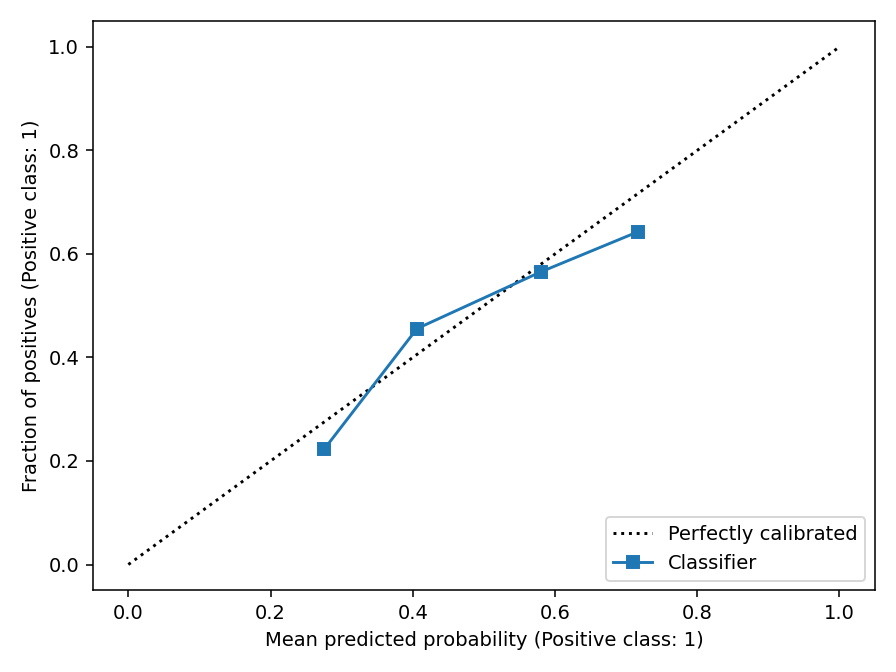

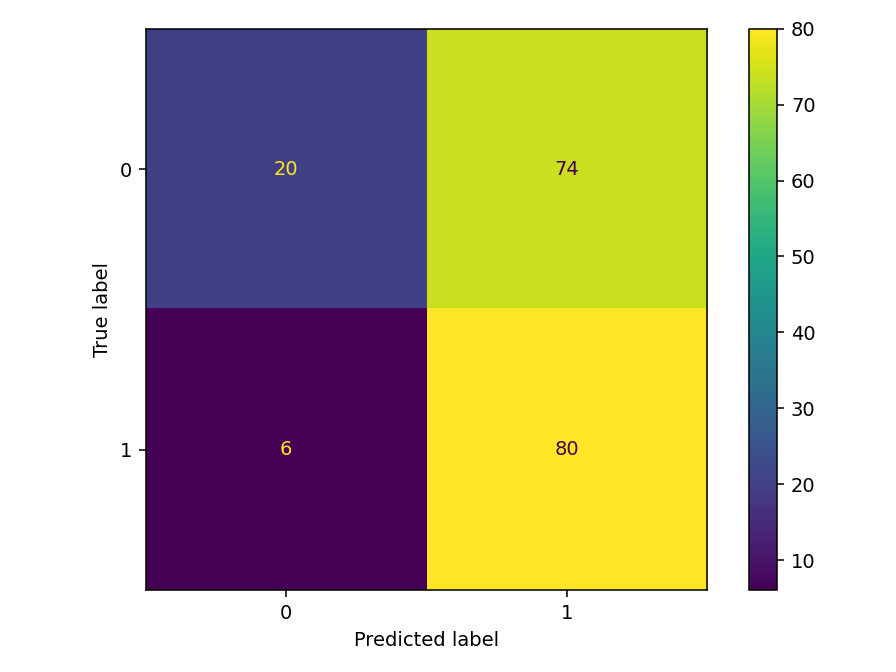

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
